# Global Pollution Analysis 

# Import libraries

In [2]:
import pandas as pd  # pandas helps us work with tabular data
import numpy as np  # numpy helps us perform numerical calculations

import matplotlib.pyplot as plt  # matplotlib helps us create visualizations
import seaborn as sns  # seaborn helps us create statistical visualizations

from sklearn.preprocessing import LabelEncoder  # LabelEncoder converts categories into numbers
from sklearn.preprocessing import StandardScaler  # StandardScaler standardizes numerical features
from sklearn.preprocessing import MinMaxScaler  # MinMaxScaler converts values into a non-negative range

from sklearn.model_selection import train_test_split  # splits data into training and testing sets
from sklearn.model_selection import GridSearchCV  # helps us find the best hyperparameters

from sklearn.pipeline import Pipeline  # Pipeline combines preprocessing and model steps

from sklearn.naive_bayes import MultinomialNB  # Multinomial Naive Bayes classifier
from sklearn.neighbors import KNeighborsClassifier  # KNN classifier
from sklearn.tree import DecisionTreeClassifier  # Decision Tree classifier

from sklearn.metrics import accuracy_score  # calculates accuracy
from sklearn.metrics import precision_score  # calculates precision
from sklearn.metrics import recall_score  # calculates recall
from sklearn.metrics import f1_score  # calculates F1-score
from sklearn.metrics import confusion_matrix  # creates confusion matrix
from sklearn.metrics import classification_report  # creates detailed classification report

pd.set_option('display.max_columns', None)  # display all columns

# Load Dataset

In [3]:
df = pd.read_csv(
    "Global_Pollution_Analysis (1).csv"
)  # read the CSV dataset into a DataFrame

df.head()  # display the first five rows


,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


# Understand the dataset

In [4]:
print("Dataset Shape:", df.shape)  # display number of rows and columns

print("\nColumn Names:")
print(df.columns)  # display all column names

print("\nData Types:")
print(df.dtypes)  # display the data type of each column

Dataset Shape: (200, 13)

Column Names:
Index(['Country', 'Year', 'Air_Pollution_Index', 'Water_Pollution_Index',
       'Soil_Pollution_Index', 'Industrial_Waste (in tons)',
       'Energy_Recovered (in GWh)', 'CO2_Emissions (in MT)',
       'Renewable_Energy (%)', 'Plastic_Waste_Produced (in tons)',
       'Energy_Consumption_Per_Capita (in MWh)', 'Population (in millions)',
       'GDP_Per_Capita (in USD)'],
      dtype='str')

Data Types:
Country                                       str
Year                                        int64
Air_Pollution_Index                       float64
Water_Pollution_Index                     float64
Soil_Pollution_Index                      float64
Industrial_Waste (in tons)                float64
Energy_Recovered (in GWh)                 float64
CO2_Emissions (in MT)                     float64
Renewable_Energy (%)                      float64
Plastic_Waste_Produced (in tons)          float64
Energy_Consumption_Per_Capita (in MWh)    float64
Pop

`Check Basic statistics`

In [5]:
df.describe()  # calculate statistical summary for numerical columns

,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
count,200.000000,200.00000,200.000000,200.000000,200.00000,200.000000,200.000000,200.000000,200.000000,200.00000,200.000000,200.000000
mean,2009.335000,180.62695,115.068100,76.488550,52891.68150,260.448700,24.878100,27.799700,24492.893550,9.43575,104.271300,35307.602400
std,5.765325,67.07331,47.580911,39.692727,27224.49169,147.141923,14.470892,12.361879,14421.356002,5.57567,56.906574,19481.714455
min,2000.000000,50.30000,31.130000,11.150000,1019.37000,11.730000,1.920000,5.040000,542.950000,0.53000,2.320000,1298.700000
25%,2004.000000,134.97250,74.550000,40.895000,31201.97250,118.355000,11.220000,17.700000,12843.882500,4.58250,60.960000,19525.020000
50%,2010.000000,183.38500,112.305000,78.600000,55299.15000,273.140000,25.355000,29.170000,24121.540000,9.22500,104.965000,35043.325000
75%,2014.000000,237.42500,157.477500,109.212500,74805.82500,384.957500,38.550000,37.072500,36516.232500,13.99750,150.930000,51629.547500
max,2019.000000,297.95000,199.320000,149.230000,99739.36000,499.980000,49.690000,49.560000,49852.280000,19.98000,198.820000,69143.140000


# Check Missing Values

In [6]:
print("Missing Values:")
print(df.isnull().sum())  # count missing values in every column

Missing Values:
Country                                   0
Year                                      0
Air_Pollution_Index                       0
Water_Pollution_Index                     0
Soil_Pollution_Index                      0
Industrial_Waste (in tons)                0
Energy_Recovered (in GWh)                 0
CO2_Emissions (in MT)                     0
Renewable_Energy (%)                      0
Plastic_Waste_Produced (in tons)          0
Energy_Consumption_Per_Capita (in MWh)    0
Population (in millions)                  0
GDP_Per_Capita (in USD)                   0
dtype: int64


In [7]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns  # select numerical columns

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)  # replace missing numerical values with the median

`For categorical data`

In [8]:
categorical_columns = df.select_dtypes(
    exclude=np.number
).columns  # select categorical columns

for column in categorical_columns:

    df[column] = df[column].fillna(
        df[column].mode()[0]
    )  # replace missing categories with the most common value

In [13]:
print(
    "Duplicate Rows:",
    df.duplicated().sum()
)  # count duplicate rows


# If Duplicate values presented use this coding

#df = df.drop_duplicates().reset_index(
#    drop=True
#)  # remove duplicate rows and reset the index

Duplicate Rows: 0


# Handle Outlier

`We will use the IQR method and cap extreme values rather than deleting observation`

In [ ]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns  # select all numerical columns

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)  # calculate first quartile

    Q3 = df[column].quantile(0.75)  # calculate third quartile

    IQR = Q3 - Q1  # calculate interquartile range

    lower_limit = Q1 - 1.5 * IQR  # calculate lower outlier boundary

    upper_limit = Q3 + 1.5 * IQR  # calculate upper outlier boundary

    df[column] = df[column].clip(
        lower_limit,
        upper_limit
    )  # cap extreme values within the acceptable range

# Encode the country and Year

In [ ]:
# Country encoder

country_encoder = LabelEncoder()  # create a LabelEncoder for Country

df['Country_Encoded'] = country_encoder.fit_transform(
    df['Country']
)  # convert country names into numerical labels

In [15]:
# Year encoder
year_encoder = LabelEncoder()  # create a LabelEncoder for Year

df['Year_Encoded'] = year_encoder.fit_transform(
    df['Year'].astype(str)
)  # convert year values into numerical labels

# Feature engineering and Energy consumption
my dataset already contains:

In [17]:
df[['Energy_Consumption_Per_Capita (in MWh)']].head()  # check the existing energy consumption per capita feature

,Energy_Consumption_Per_Capita (in MWh)
0,12.56
1,5.23
2,13.15
3,0.78
4,12.84


# Create Pollution score 

`We will combine the three pollution indices.`

In [18]:
pollution_columns = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index'
]  # select the three pollution measurements

df['Pollution_Score'] = df[
    pollution_columns
].mean(axis=1)  # calculate the average pollution level

In [19]:
df[
    ['Air_Pollution_Index',
     'Water_Pollution_Index',
     'Soil_Pollution_Index',
     'Pollution_Score']
].head()

,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Pollution_Score
0,272.70,124.27,51.95,149.640000
1,86.72,60.34,117.22,88.093333
2,91.59,83.36,121.72,98.890000
3,280.61,67.16,93.58,147.116667
4,179.16,127.53,121.55,142.746667


# Create Yearly Pollution Trend

In [20]:
yearly_pollution = df.groupby(
    'Year'
)['Pollution_Score'].mean()  # calculate average pollution for each year

yearly_pollution

Year
2000    128.530667
2001     97.745926
2002    124.541282
2003    145.623333
2004    120.599697
2005    120.307778
2006    137.652222
2007    112.510606
2008    124.135238
2009    122.824667
2010    137.507500
2011    117.467949
2012    134.429231
2013    115.360000
2014    121.002667
2015    117.967778
2016    123.678333
2017    133.298810
2018    145.882667
2019    114.552963
Name: Pollution_Score, dtype: float64

In [22]:
# Now add the yearly value to very crresponding row. 

df['Yearly_Pollution_Trend'] = df['Year'].map(yearly_pollution)  # assign the average pollution level of that year

# Create Pollution Severity

In [23]:
df['Pollution_Severity'] = pd.qcut(df['Pollution_Score'],q=3,labels=['Low', 'Medium', 'High'])  # divide pollution scores into three severity categories

In [24]:
print(
    df['Pollution_Severity'].value_counts()
)  # count countries in each pollution category

Pollution_Severity
Low       67
High      67
Medium    66
Name: count, dtype: int64


# Scaler Pollution Indices

In [25]:
pollution_scaler = StandardScaler()  # create a standard scaler

df[
    ['Air_Pollution_Scaled',
     'Water_Pollution_Scaled',
     'Soil_Pollution_Scaled']
] = pollution_scaler.fit_transform(
    df[pollution_columns]
)  # standardize air, water, and soil pollution

# Classification

`Select Features and Target`


In [27]:
features = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index',
    'Industrial_Waste (in tons)',
    'CO2_Emissions (in MT)',
    'Renewable_Energy (%)',
    'Plastic_Waste_Produced (in tons)',
    'Energy_Consumption_Per_Capita (in MWh)',
    'Population (in millions)',
    'GDP_Per_Capita (in USD)',
    'Yearly_Pollution_Trend',
    'Year_Encoded'
]  # select features for machine learning

X = df[features]  # create the feature matrix

y = df['Pollution_Severity']  # create the target variable

# Train-Test Split

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)  # split the data into training and testing sets

# Evaluation and Function

In [29]:
def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(
        X_test
    )  # make predictions using the trained model

    accuracy = accuracy_score(
        y_test,
        y_pred
    )  # calculate accuracy

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted'
    )  # calculate weighted precision

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted'
    )  # calculate weighted recall

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )  # calculate weighted F1-score

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-score :", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred
        )
    )  # display detailed classification metrics

    return y_pred

# Multinomial Naive Bayes

In [30]:
nb_pipeline = Pipeline([
    (
        'scaler',
        MinMaxScaler()
    ),  # convert features into a non-negative range

    (
        'model',
        MultinomialNB()
    )  # create the Multinomial Naive Bayes model
])

In [31]:
# Train 
nb_pipeline.fit(
    X_train,
    y_train
)  # train the Naive Bayes model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U6](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Air_Pollution_Index','Water_Pollution_Index','Soil_Pollution_Index',..., 'GDP_Per_Capita (in USD)','Yearly_Pollution_Trend','Year_Encoded']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [32]:
print("Multinomial Naive Bayes")

y_pred_nb = evaluate_model(
    nb_pipeline,
    X_test,
    y_test
)

Multinomial Naive Bayes
Accuracy : 0.475
Precision: 0.4821
Recall   : 0.475
F1-score : 0.478

Classification Report:
              precision    recall  f1-score   support

        High       0.47      0.50      0.48        14
         Low       0.75      0.69      0.72        13
      Medium       0.23      0.23      0.23        13

    accuracy                           0.47        40
   macro avg       0.48      0.47      0.48        40
weighted avg       0.48      0.47      0.48        40



# Naive Bayes COnfusion Matrix 

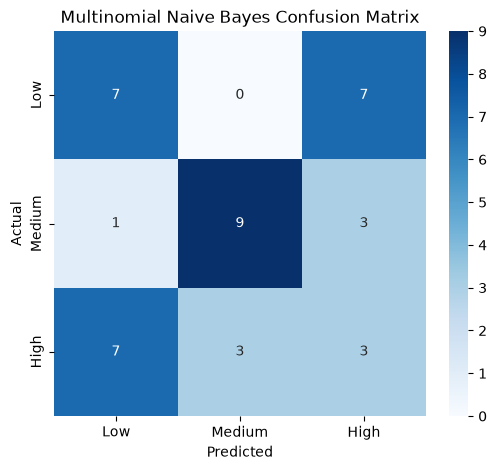

In [33]:
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb
)  # create the Naive Bayes confusion matrix

plt.figure(figsize=(6, 5))  # create the figure

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)  # display the confusion matrix

plt.title('Multinomial Naive Bayes Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# KNN - Hyperparameter Tuning 

In [34]:
knn_pipeline = Pipeline([
    (
        'scaler',
        StandardScaler()
    ),  # standardize the features for KNN

    (
        'model',
        KNeighborsClassifier()
    )  # create the KNN model
])

In [35]:
# Test Different k values 
knn_parameters = {
    'model__n_neighbors': range(3, 21, 2)
}  # test odd K values from 3 to 19

In [36]:
# Grid Search 
knn_grid = GridSearchCV(
    knn_pipeline,
    knn_parameters,
    cv=5,
    scoring='accuracy'
)  # perform 5-fold cross-validation for KNN

In [38]:
# Train 

knn_grid.fit(
    X_train,
    y_train
)  # find the best K using cross-validation

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': range(3, 21, 2)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed durin

In [39]:
# Best k 
print(
    "Best K:",
    knn_grid.best_params_
)  # display the best number of neighbors

print(
    "Best CV Accuracy:",
    round(knn_grid.best_score_, 4)
)  # display the best cross-validation accuracy

Best K: {'model__n_neighbors': 7}
Best CV Accuracy: 0.725


In [40]:
# Evaluate
print("\nKNN")

y_pred_knn = evaluate_model(
    knn_grid.best_estimator_,
    X_test,
    y_test
)


KNN
Accuracy : 0.6
Precision: 0.5679
Recall   : 0.6
F1-score : 0.5724

Classification Report:
              precision    recall  f1-score   support

        High       0.63      0.86      0.73        14
         Low       0.69      0.69      0.69        13
      Medium       0.38      0.23      0.29        13

    accuracy                           0.60        40
   macro avg       0.57      0.59      0.57        40
weighted avg       0.57      0.60      0.57        40



# KNN Confusion Matrix 

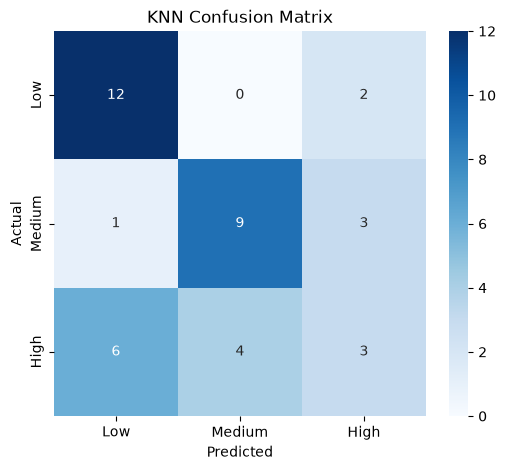

In [41]:
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)  # create the KNN confusion matrix

plt.figure(figsize=(6, 5))  # create the figure

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)  # display the confusion matrix

plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Decision Tree - Hyperparamater Tuning 

In [42]:
dt_model = DecisionTreeClassifier(
    random_state=42
)  # create the Decision Tree classifier

In [43]:
dt_parameters = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10, 20]
}  # define tree parameters to control overfitting

# Grid Search 


In [44]:
dt_grid = GridSearchCV(
    dt_model,
    dt_parameters,
    cv=5,
    scoring='accuracy'
)  # perform 5-fold cross-validation

In [46]:
# Train 
dt_grid.fit(
    X_train,
    y_train
)  # find the best Decision Tree parameters


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of info

In [47]:
# Display the best parameters:
print(
    "Best Parameters:",
    dt_grid.best_params_
)  # display the best tree parameters

print(
    "Best CV Accuracy:",
    round(dt_grid.best_score_, 4)
)  # display the best cross-validation accuracy

Best Parameters: {'max_depth': 5, 'min_samples_split': 10}
Best CV Accuracy: 0.7188


In [48]:
# Evaluate Decision Tree

print("Decision Tree")

y_pred_dt = evaluate_model(
    dt_grid.best_estimator_,
    X_test,
    y_test
)

Decision Tree
Accuracy : 0.775
Precision: 0.7844
Recall   : 0.775
F1-score : 0.7772

Classification Report:
              precision    recall  f1-score   support

        High       0.80      0.86      0.83        14
         Low       0.91      0.77      0.83        13
      Medium       0.64      0.69      0.67        13

    accuracy                           0.78        40
   macro avg       0.78      0.77      0.78        40
weighted avg       0.78      0.78      0.78        40



# Decision Tree COnfusion Matrix 

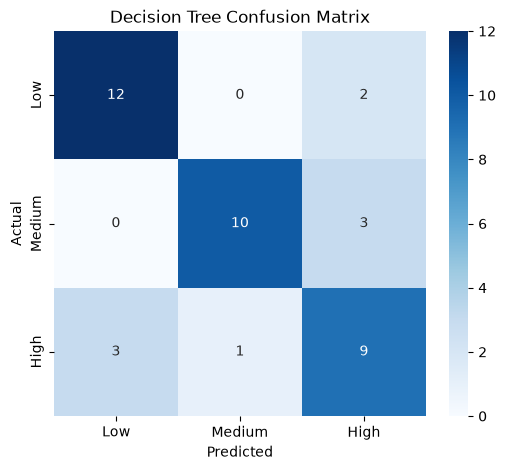

In [49]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt
)  # create the Decision Tree confusion matrix

plt.figure(figsize=(6, 5))  # create the figure

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)  # display the confusion matrix

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Model Comparison

In [50]:
results = pd.DataFrame({

    'Model': [
        'Multinomial Naive Bayes',
        'KNN',
        'Decision Tree'
    ],  # store model names

    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt)
    ],  # calculate accuracy for each model

    'Precision': [
        precision_score(y_test, y_pred_nb, average='weighted'),
        precision_score(y_test, y_pred_knn, average='weighted'),
        precision_score(y_test, y_pred_dt, average='weighted')
    ],  # calculate precision

    'Recall': [
        recall_score(y_test, y_pred_nb, average='weighted'),
        recall_score(y_test, y_pred_knn, average='weighted'),
        recall_score(y_test, y_pred_dt, average='weighted')
    ],  # calculate recall

    'F1-Score': [
        f1_score(y_test, y_pred_nb, average='weighted'),
        f1_score(y_test, y_pred_knn, average='weighted'),
        f1_score(y_test, y_pred_dt, average='weighted')
    ]  # calculate F1-score
})

results = results.round(4)  # round the evaluation values

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.475,0.4821,0.475,0.4780
1,KNN,0.600,0.5679,0.600,0.5724
2,Decision Tree,0.775,0.7844,0.775,0.7772


# Visualize Model Performance 

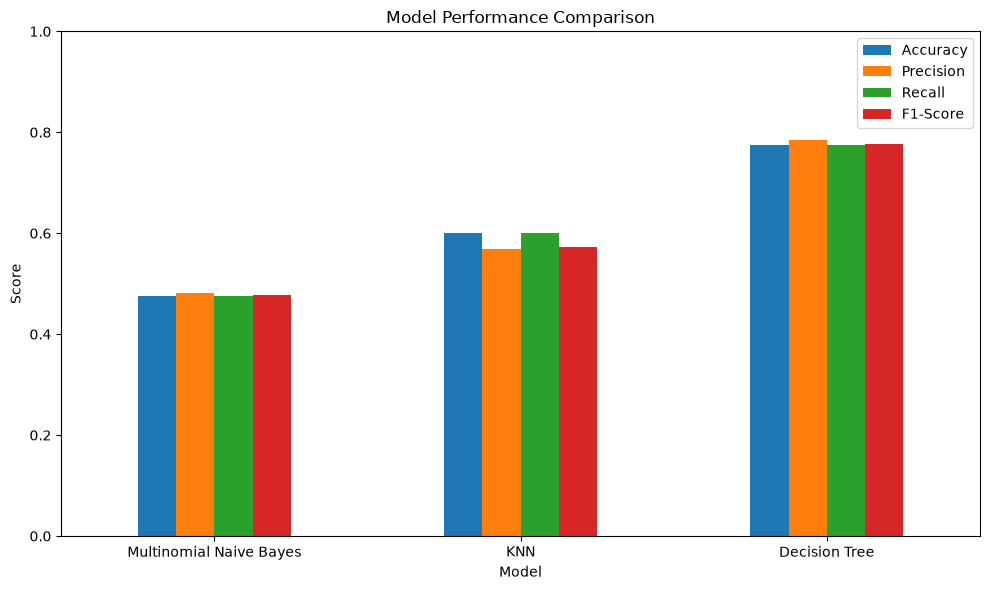

In [51]:
results.set_index(
    'Model'
)[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].plot(
    kind='bar',
    figsize=(10, 6)
)  # create a bar chart comparing all models

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

# Compare confusion matrices togather 

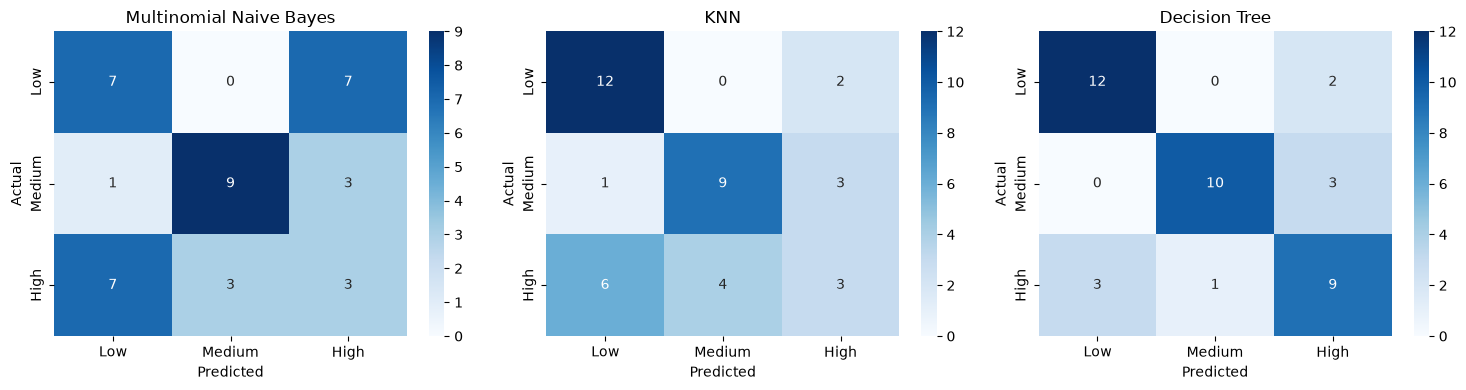

In [52]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)  # create three plots in one row

matrices = [
    (cm_nb, 'Multinomial Naive Bayes'),
    (cm_knn, 'KNN'),
    (cm_dt, 'Decision Tree')
]  # store confusion matrices and model names

for ax, (cm, title) in zip(axes, matrices):

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Low', 'Medium', 'High'],
        yticklabels=['Low', 'Medium', 'High'],
        ax=ax
    )  # display each confusion matrix

    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Find the best model 

In [53]:
best_model = results.loc[
    results['F1-Score'].idxmax()
]  # find the model with the highest F1-score

print("Best Model:", best_model['Model'])
print("Accuracy:", best_model['Accuracy'])
print("Precision:", best_model['Precision'])
print("Recall:", best_model['Recall'])
print("F1-Score:", best_model['F1-Score'])

Best Model: Decision Tree
Accuracy: 0.775
Precision: 0.7844
Recall: 0.775
F1-Score: 0.7772


# Pollution Severity vs Energy Recovery 

In [54]:
energy_analysis = df.groupby(
    'Pollution_Severity'
)[
    'Energy_Recovered (in GWh)'
].agg(
    ['mean', 'min', 'max']
).round(2)  # calculate energy recovery statistics for each severity category

energy_analysis

,mean,min,max
Pollution_Severity,,,
Low,255.66,13.22,498.04
Medium,277.09,28.87,495.28
High,248.84,11.73,499.98


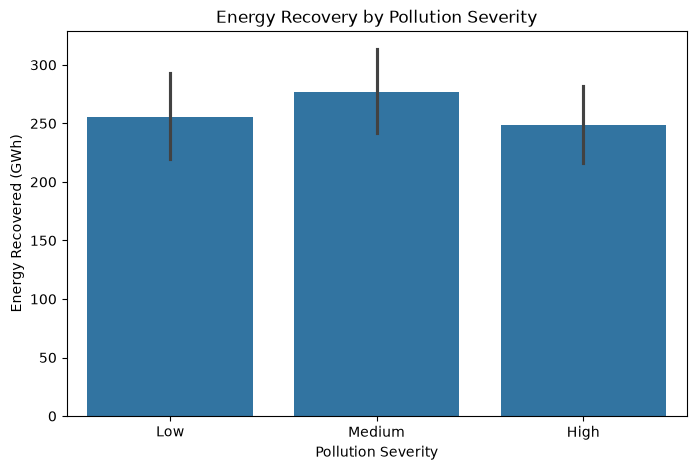

In [56]:
# Visualize it: 

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Pollution_Severity',
    y='Energy_Recovered (in GWh)',
    order=['Low', 'Medium', 'High']
)  # compare average energy recovery across pollution categories

plt.title('Energy Recovery by Pollution Severity')
plt.xlabel('Pollution Severity')
plt.ylabel('Energy Recovered (GWh)')
plt.show()

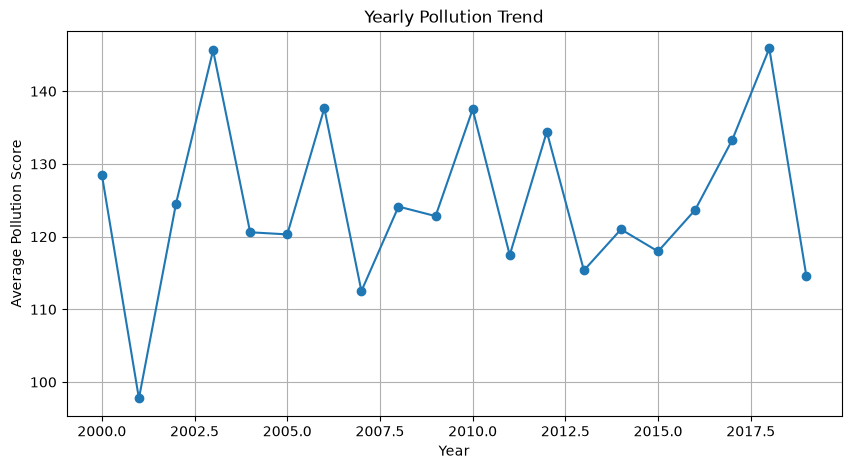

In [58]:
# Pollution Trend Over the years 
trend = df.groupby(
    'Year'
)['Pollution_Score'].mean()  # calculate average pollution score for each year

plt.figure(figsize=(10, 5))

plt.plot(
    trend.index,
    trend.values,
    marker='o'
)  # plot pollution trend over time

plt.title('Yearly Pollution Trend')
plt.xlabel('Year')
plt.ylabel('Average Pollution Score')
plt.grid(True)
plt.show()

# Country - Level Pollution Analysis 

In [59]:
country_analysis = df.groupby(
    'Country'
)[
    [
        'Pollution_Score',
        'Energy_Recovered (in GWh)'
    ]
].mean().sort_values(
    'Pollution_Score',
    ascending=False
)  # calculate average pollution and energy recovery by country

country_analysis.head(10)

,Pollution_Score,Energy_Recovered (in GWh)
Country,,
Saint Barthelemy,187.036667,390.35
Bolivia,181.496667,93.73
Central African Republic,177.016667,499.98
Christmas Island,175.950000,22.21
Papua New Guinea,175.660000,333.14
Guinea-Bissau,175.353333,322.06
Morocco,174.250000,355.02
Philippines,173.636667,232.33
Saint Lucia,173.626667,120.87


# Summary 

Final Report
Global Pollution Analysis — Final Report
This project classified countries into Low, Medium, and High pollution-severity categories using environmental, energy, waste, and economic factors. Data preprocessing included missing-value checking, outlier treatment, categorical encoding, feature engineering, and feature scaling. Multinomial Naive Bayes, KNN, and Decision Tree classifiers were implemented and evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices. KNN and Decision Tree were optimized using cross-validation and hyperparameter tuning. The best classifier should be selected according to the highest F1-score, while Decision Tree provides strong interpretability. The analysis can support environmental monitoring, waste management, renewable-energy planning, and targeted pollution-reduction policies.